# Trabalho Final — Pipeline do Ciclo de Ciência de Dados
**Disciplina:** Ciência de Dados  
**Professora:** Trícia Santos Souto  
**Equipe:** Lavínia Souza Caló de Figueiredo, Lucas Luige Costa Miranda e Sara Raquel Pinto Brandão Silva  
**Base de Dados:** Stack Overflow Developer Survey (Edição 2024 / Módulo de IA e AI Agents)  
**Tema:** Determinantes e Preditores da Adoção de Agentes de Inteligência Artificial por Desenvolvedores Profissionais  
**Entrega 1 (Semana 1):** Revisão da AED (Bloco A: Fases 0 a 5) + Modelagem e Particionamento (Bloco B: Fases 6 e 7)  

> **Nota sobre a Revisão da Etapa 1 (Pós-Apresentação):**  
> A partir dos apontamentos recebidos na primeira etapa e visando preparar a base para modelagem preditiva robusta, realizamos **5 aprimoramentos concretos** no Bloco A em relação à entrega anterior:  
> 1. **Unificação do Alvo (Caminho A):** Todas as hipóteses convergem para o único desfecho supervisionado (`AIAgents_bin`), eliminando alvos concorrentes.  
> 2. **Prevenção Estrita de Vazamento (*Target Leakage*):** Isolamento preventivo de `AISelect` (tautologia direta) e, no Bloco B (Fase 7), reestimação de todo o pré-processamento que aprende com os dados (cercas de outlier, imputação isBAD, padronização e *target encoding*) exclusivamente no treino, via `Pipeline` do scikit-learn.  
> 3. **Incorporação de Tamanho de Efeito na Fase 3:** Em amostras grandes ($N >$ 24 mil), o $p$-valor tende a $0$ facilmente; adicionamos o $V$ de Cramér (categóricas) e a correlação *rank-biserial* (contínuas), com um gráfico de ranqueamento prático para distinguir associações fortes de fracas.  
> 4. **Verificação da Direção das Hipóteses:** Os testes Qui-Quadrado e Mann-Whitney bilaterais só indicam *se* há associação; passamos a verificar programaticamente se o *sentido* observado é o previsto em cada hipótese direcional, e o quadro final de hipóteses é gerado a partir desses resultados.  
> 5. **Diagnóstico de Forma Funcional (LOESS — Fase 5):** Curvas de suavização local nos preditores contínuos sobreviventes (`JobSat` e `YearsCode`), usadas para avaliar linearidade/monotonicidade antes da escolha dos modelos do Bloco B.  

---

## Pré-requisito: recorte de escopo do domínio (antes da Fase 0)

Antes do início do pipeline de auditoria (Fase 0 em diante), é aplicado **um único recorte de escopo de negócio**, não relacionado a problemas de qualidade de dados, NAs ou outliers: são mantidos apenas respondentes com `MainBranch == "I am a developer by profession"`. 

Esse filtro define a **população de estudo** (desenvolvedores profissionais, não estudantes, hobbistas ou ex-desenvolvedores, cujas respostas distorceriam sistematicamente perguntas de carreira e remuneração). Trata-se de uma decisão de design da pesquisa, tomada antes de qualquer análise de dados; por isso, não constitui o tipo de "descarte físico de linhas" que a Fase 0 proíbe. A partir deste ponto, a base recortada é tratada como a "base original" preservada intacta ao longo das Fases 0 e 1.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    balanced_accuracy_score, classification_report, make_scorer
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

RNG_SEED = 42
np.random.seed(RNG_SEED)

audit_trail = []

def registrar_auditoria(fase, variavel, status, justificativa):
    audit_trail.append({
        'Fase': fase,
        'Variável': variavel,
        'Status': status,
        'Justificativa': justificativa
    })

print("Ambiente configurado com sucesso. Semente fixa:", RNG_SEED)

Ambiente configurado com sucesso. Semente fixa: 42


## Fase 0: Inspeção Inicial e Formulação Condicional de Hipóteses (Pré-AED)

Nesta fase inicial, realizamos a leitura automatizada da base de dados sem alterações físicas, avaliamos a existência de desfecho para bifurcação do caminho analítico (Caminho A vs. Caminho B) e registramos as hipóteses causais do negócio.

### Passo 0.1: Raio-X de Metadados e Seleção Temática

Leitura automatizada do dicionário oficial (`survey_results_schema.csv`) e da base bruta, **sem nenhuma alteração física**: são apenas listados colunas, formatos e tipos.

In [44]:
schema = pd.read_csv("survey_results_schema.csv")
print("Dicionário oficial, total de perguntas/colunas documentadas:", len(schema))
schema.head(10)

Dicionário oficial, total de perguntas/colunas documentadas: 139


,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0
5,QID18,TechEndorse_6,What attracts you to a technology or causes yo...,RO,Connected to an open-source project,6.0
6,QID18,TechEndorse_7,What attracts you to a technology or causes yo...,RO,Good brand and public image,7.0
7,QID18,TechEndorse_8,What attracts you to a technology or causes yo...,RO,Reliability and low latency,8.0
8,QID18,TechEndorse_9,What attracts you to a technology or causes yo...,RO,Costs are manageable,9.0
9,QID18,TechEndorse_13,What attracts you to a technology or causes yo...,RO,Other (please specify):,10.0


In [45]:
raw_header = pd.read_csv("survey_results_public.csv", nrows=0)
print("Total de colunas na base bruta:", len(raw_header.columns))

COLS = [
    "ResponseId", "MainBranch",
    "Age", "EdLevel", "Employment", "WorkExp", "YearsCode", "DevType", "OrgSize",
    "ICorPM", "RemoteWork", "Country", "Industry", "JobSat", "ConvertedCompYearly",
    "AIThreat", "AISelect", "AISent", "AIAcc", "AIComplex", "AIAgents", "SOVisitFreq"
]

df_raw = pd.read_csv("survey_results_public.csv", usecols=COLS, na_values=["NA"], low_memory=False)
print(f"Linhas na base bruta: {len(df_raw)}")

df = df_raw[df_raw["MainBranch"] == "I am a developer by profession"].drop(columns=["MainBranch"]).reset_index(drop=True)
print(f"Linhas após recorte de escopo (devs profissionais): {len(df)}")

CONTINUOUS = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly"]
for c in CONTINUOUS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("\nTipos de dados (Raio-X pós seleção de colunas de resposta única):")
df.dtypes.to_frame('Tipo de Dado')

Total de colunas na base bruta: 172
Linhas na base bruta: 49191
Linhas após recorte de escopo (devs profissionais): 37467

Tipos de dados (Raio-X pós seleção de colunas de resposta única):


,Tipo de Dado
ResponseId,int64
Age,str
EdLevel,str
Employment,str
WorkExp,float64
YearsCode,float64
DevType,str
OrgSize,str
ICorPM,str
RemoteWork,str


**Colunas descartadas do pipeline (Fase 0, critério de dados administrativos/controle):**

- `ResponseId` é mantida apenas como **identificador de linha** (chave sequencial de controle); não é utilizada como preditor em nenhuma etapa estatística ou de modelagem a partir daqui. É o único caso análogo a "ID de controle" citado no roteiro. Nenhuma outra coluna do subconjunto é 100% constante ou puramente administrativa.
- As demais **151 colunas da base bruta (de 172)** já haviam sido descartadas na definição do escopo do trabalho: a grande maioria é composta por perguntas de múltipla escolha ("selecione todas que se aplicam") ou de rankings compostos (valores separados por `;`), fora do escopo desta análise de variáveis de resposta única.

### Passo 0.2: O Teste do Rótulo e Decisão de Caminho

Avaliamos se a base possui uma variável representativa de desfecho do negócio para bifurcar formalmente o percurso metodológico:
- **Caminho A (Supervisionado):** Existência de alvo preditivo bem discriminado.
- **Caminho B (Não Supervisionado):** Ausência de alvo (foco em agrupamento e mapeamento geométrico).

In [46]:
def binarizar_ai_agents(val):
    if pd.isna(val):
        return np.nan
    adotantes = {
        "Yes, I use AI agents at work daily",
        "Yes, I use AI agents at work weekly",
        "Yes, I use AI agents at work monthly or infrequently"
    }
    nao_adotantes = {
        "No, and I don't plan to",
        "No, I use AI exclusively in copilot/autocomplete mode",
        "No, but I plan to"
    }
    if val in adotantes:
        return 1.0
    if val in nao_adotantes:
        return 0.0
    return np.nan

df["AIAgents_bin"] = df["AIAgents"].apply(binarizar_ai_agents)

print("Distribuição de respostas no alvo original (AIAgents):")
print(df["AIAgents"].value_counts(dropna=False))
print("\nDistribuição do alvo binário na base de estudo (incluindo ausentes de resposta):")
print(df["AIAgents_bin"].value_counts(dropna=False))
pct_na_alvo = df["AIAgents_bin"].isna().mean() * 100
print(f"\nProporção de ausência no alvo original: {pct_na_alvo:.2f}%")

Distribuição de respostas no alvo original (AIAgents):
AIAgents
NaN                                                      12684
No, and I don't plan to                                   9091
No, but I plan to                                         4272
Yes, I use AI agents at work daily                        3692
No, I use AI exclusively in copilot/autocomplete mode     3524
Yes, I use AI agents at work weekly                       2289
Yes, I use AI agents at work monthly or infrequently      1915
Name: count, dtype: int64

Distribuição do alvo binário na base de estudo (incluindo ausentes de resposta):
AIAgents_bin
0.0    16887
NaN    12684
1.0     7896
Name: count, dtype: int64

Proporção de ausência no alvo original: 33.85%


**Decisão Formal: Caminho A (Aprendizado Supervisionado).**

A variável `AIAgents` ("uso de agentes autônomos de IA no fluxo de trabalho") constitui o tema central desta edição da pesquisa e possui valor direto de negócio: prever prontidão e adoção de agentes de IA para direcionamento de treinamento e produtos corporativos.

Mapeamos as respostas originais em um alvo binário (`AIAgents_bin`):
- **Classe 1 (Adotante):** Desenvolvedores que utilizam agentes de IA diariamente, semanalmente ou mensalmente no trabalho.
- **Classe 0 (Não Adotante):** Desenvolvedores que não utilizam (nem planejam), planejam usar ou utilizam IA exclusivamente em modo copiloto/autocomplete.

**Tratamento da Ausência no Rótulo:**  
Cerca de 33,9% dos desenvolvedores profissionais (32,7% após a remoção de linhas da Fase 1) pularam o bloco temático de agentes de IA (pesquisa paginada opcional). Em aprendizado supervisionado, **não se deve imputar valores sintéticos na variável-alvo** (isso geraria contaminação e rótulos artificiais). Portanto, as linhas sem rótulo representam a partição não-rotulada, sendo isoladas da esteira supervisionada na entrada da Fase 3 e modelagem.

### Passo 0.3: Guia de Hipóteses Formais e Prevenção de Vazamento Prematuro

Formulamos 6 hipóteses causais formais ($X \to Y$), com $Y = \text{AIAgents\_bin}$, amparadas no domínio do negócio:

| ID | Hipótese Inicial | Preditores ($X$) | Teste Estatístico (Fase 3) | Justificativa de Negócio |
|---|---|---|---|---|
| **H1** | Desenvolvedores mais experientes (maior `WorkExp` / `YearsCode`) apresentam **menor** probabilidade de uso de agentes de IA, refletindo adoção mais cautelosa e menor necessidade percebida em comparação a devs juniores. | `WorkExp`, `YearsCode` (contínuas) | Mann-Whitney + *rank-biserial* | Desenvolvedores mais experientes possuem fluxos consolidados e maior cautela em relação a ferramentas geradoras de código. |
| **H2** | O uso de agentes de IA está associado ao cargo/função (`DevType`) e ao tamanho da empresa (`OrgSize`), com maior adoção esperada em funções mais técnicas e empresas maiores/mais estruturadas. | `DevType`, `OrgSize` (categóricas) | Qui-Quadrado + V de Cramér | Papéis especializados e empresas maiores possuem mais estrutura ou incentivo para testes com agentes. |
| **H3** | Maior confiança na precisão da IA (`AIAcc`) e melhor percepção de desempenho em tarefas complexas (`AIComplex`) associam-se a **maior** probabilidade de uso de agentes de IA. | `AIAcc`, `AIComplex` (ordinais) | Qui-Quadrado + V de Cramér | A confiança nas saídas do agente é pré-requisito comportamental para delegar tarefas autônomas. |
| **H4** | A satisfação no cargo (`JobSat`) está associada ao uso de agentes de IA (hipótese de produtividade percebida). | `JobSat` (contínua) | Mann-Whitney + *rank-biserial* | Desenvolvedores que adotam ferramentas autônomas relatam alívio de tarefas repetitivas, impactando a satisfação. |
| **H5** | O modelo de trabalho (`RemoteWork`) e o papel (`ICorPM`) estão associados à adoção, sob a hipótese de que trabalho remoto e contribuidores individuais adotam mais (uso mais autônomo de ferramentas). | `RemoteWork`, `ICorPM` (categóricas) | Qui-Quadrado + V de Cramér | Profissionais em regime remoto e contribuidores individuais têm maior autonomia para experimentar ferramentas. |
| **H6** | Maior frequência de visita ao Stack Overflow (`SOVisitFreq`) associa-se a **menor** uso de agentes de IA, com a comunidade tradicional funcionando como substituto parcial. | `SOVisitFreq` (ordinal) | Qui-Quadrado + V de Cramér | Comunidades tradicionais de Q&A funcionam como substitutas parciais da assistência direta por IA. |

**Critério de descarte de hipóteses aplicado neste ponto:** nenhuma das hipóteses acima depende de preditor ausente da base ou de proxy excessivamente fraca; todas as variáveis citadas existem no subconjunto de 20 colunas selecionado.

**Exploração secundária (fora do escopo formal de H1 a H6, não testada com o rigor do Caminho A):** `AIThreat`, `AISent` e `ConvertedCompYearly` também apresentam relação plausível com adoção de IA, mas a manutenção de um único alvo (`AIAgents_bin`) evita diluir o timebox de duas semanas em múltiplos pipelines de rótulo. Trata-se de um critério de parada justificado pelas hipóteses definidas, não apenas pelo tempo.

**Descarte por redundância/vazamento (leakage):** `AISelect` ("uso de ferramentas de IA no desenvolvimento") é descartada do conjunto de preditores. Embora não seja idêntica ao rótulo, é uma proxy quase direta: "usar ferramentas de IA" é quase uma pré-condição de "usar agentes de IA", o que tornaria qualquer associação estatisticamente óbvia e pouco informativa (tautologia), violando a diretriz de evitar obviedades estatísticas.

**Descarte de Atributo Administrativo:**  
`ResponseId` é mantido apenas como chave sequencial de auditoria, sendo excluído da modelagem preditiva.

In [47]:
df_outcomes = df[["ResponseId", "AIAgents", "AISelect", "AIAgents_bin"]].copy()

registrar_auditoria("Fase 0", "AISelect", "Descartada (preditor)",
                    "Proxy quase direta do alvo (vazamento/tautologia). Guardada em df_outcomes.")
registrar_auditoria("Fase 0", "ResponseId", "Mantida (não-preditora)",
                    "Chave primária sequencial de controle operacional, sem poder explicativo.")

df = df.drop(columns=["AISelect"])
CATEGORICAL = [c for c in df.columns if c not in CONTINUOUS + ["ResponseId", "AIAgents", "AIAgents_bin"]]
print("Preditores categóricos remanescentes:", CATEGORICAL)

Preditores categóricos remanescentes: ['Age', 'EdLevel', 'Employment', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'Industry', 'AIThreat', 'Country', 'SOVisitFreq', 'AISent', 'AIAcc', 'AIComplex']


## Fase 1: Análise Univariada e Condicionamento de Dados (Data Conditioning)

Nesta fase: (1) a normalidade é testada formalmente com Shapiro-Wilk; (2) inconsistências físicas são convertidas em NA e outliers extremos são isolados e também convertidos em NA; (3) todos os NAs (originais e gerados por outliers) são tratados cientificamente pelo método **isBAD**, sem nenhum descarte ingênuo de linhas (`complete cases`).

### Normalidade (Shapiro-Wilk)

O teste de Shapiro-Wilk é recomendado para amostras de até ~5.000 observações (acima disso a estatística fica pouco sensível e o p-valor tende a rejeitar quase qualquer desvio mínimo da normalidade). Por isso o teste é executado em uma amostra aleatória de até 5.000 observações por variável (`random_state=42`, reprodutível), acompanhado de gráficos de densidade sobre a distribuição completa.

In [48]:
def shapiro_sample(s, n=5000, seed=RNG_SEED):
    s = s.dropna()
    if len(s) > n:
        s = s.sample(n, random_state=seed)
    stat, p = stats.shapiro(s)
    return pd.Series({"n_testado": len(s), "estatistica_W": round(stat, 4), "p_valor": p,
                       "eh_normal_alpha_0.05": "Sim" if p >= 0.05 else "Não"})

shapiro_report = pd.DataFrame({c: shapiro_sample(df[c]) for c in CONTINUOUS}).T
shapiro_report

,n_testado,estatistica_W,p_valor,eh_normal_alpha_0.05
WorkExp,5000,0.8778,0.0,Não
YearsCode,5000,0.9225,0.0,Não
JobSat,5000,0.9116,0.0,Não
ConvertedCompYearly,5000,0.1212,0.0,Não


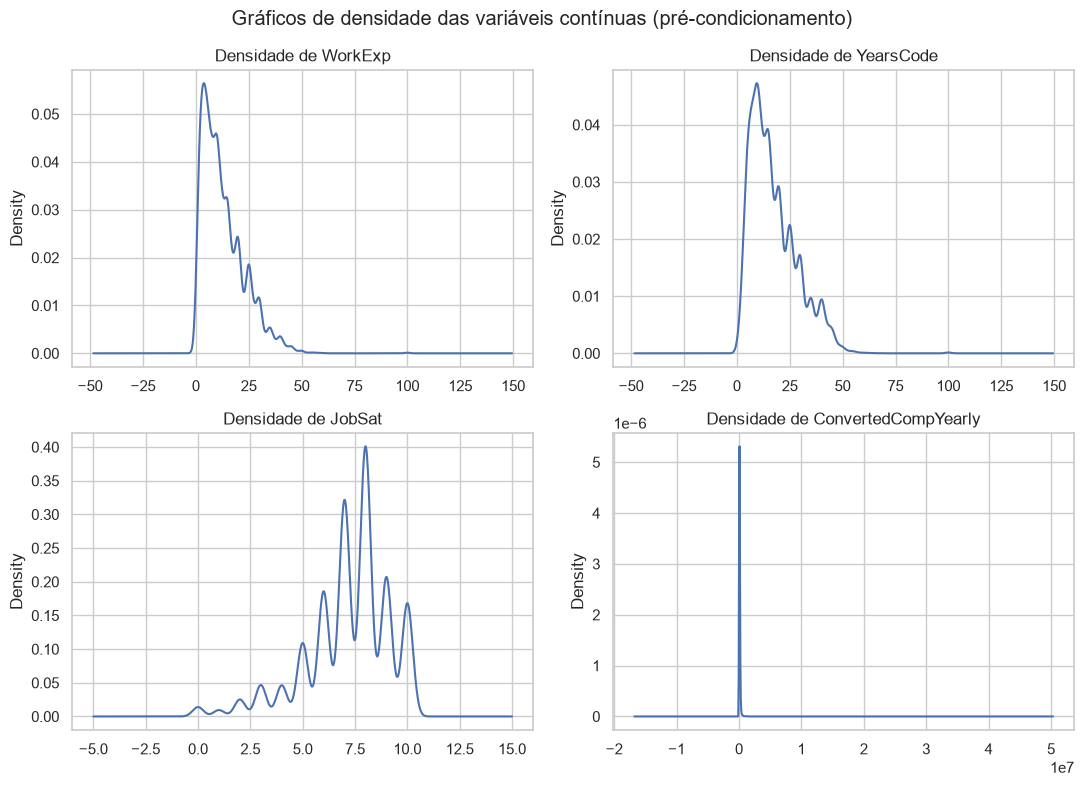

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, c in zip(axes.flat, CONTINUOUS):
    df[c].dropna().plot(kind="density", ax=ax, color="#4C72B0")
    ax.set_title(f"Densidade de {c}")
plt.suptitle("Gráficos de densidade das variáveis contínuas (pré-condicionamento)")
plt.tight_layout()
plt.show()

**H0 rejeitada (p < 0.05) para as 4 variáveis contínuas.** Nenhuma segue distribuição normal de Gauss, o que confirma, já na Fase 1, que os testes bivariados da Fase 3 devem ser **não-paramétricos baseados em postos** (Wilcoxon/Mann-Whitney), conforme já antecipado nas hipóteses H1 e H4 da Fase 0.

### Inconsistências físicas e outliers extremos

Primeiramente, é convertido em NA qualquer valor que viole regras físicas do domínio (idade/experiência/remuneração negativas, `JobSat` fora da escala de 0 a 10 da pesquisa). Em seguida, outliers de medição extremos são isolados via IQR (limiar de 3×IQR, seguindo a convenção de "outlier extremo" de Tukey, mais conservadora que o 1,5×IQR de "outlier comum", de modo a não descartar informação demais em variáveis já sabidamente assimétricas) e também convertidos em NA, a serem tratados no mesmo pipeline isBAD.

In [50]:
invalid_mask = pd.DataFrame({
    "WorkExp": df["WorkExp"] < 0,
    "YearsCode": df["YearsCode"] < 0,
    "JobSat": (df["JobSat"] < 0) | (df["JobSat"] > 10),
    "ConvertedCompYearly": df["ConvertedCompYearly"] <= 0,
})

for c in CONTINUOUS:
    n_flag = invalid_mask[c].sum()
    df.loc[invalid_mask[c], c] = np.nan
    print(f"{c}: {n_flag} valores fisicamente inválidos convertidos em NA")

# Snapshot após as regras físicas determinísticas (nada aqui é aprendido com os dados).
# É a entrada do Pipeline do Bloco B (Fase 7): cercas de outlier, medianas, z-score e
# target encoding serão reestimados lá, somente no conjunto de treino.
df_pre_aprendizado = df.copy()

WorkExp: 0 valores fisicamente inválidos convertidos em NA
YearsCode: 0 valores fisicamente inválidos convertidos em NA
JobSat: 0 valores fisicamente inválidos convertidos em NA
ConvertedCompYearly: 0 valores fisicamente inválidos convertidos em NA


In [51]:
def extreme_outlier_mask(s, k=3.0):
    s_valid = s.dropna()
    q1, q3 = s_valid.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return (s < low) | (s > high), low, high

outlier_report_rows = []
for c in CONTINUOUS:
    mask, low, high = extreme_outlier_mask(df[c])
    mask = mask.fillna(False)
    qtd_outliers = int(mask.sum())
    outlier_report_rows.append({
        "variável": c, "limite_inf": round(low, 2), "limite_sup": round(high, 2),
        "n_outliers_extremos": qtd_outliers,
        "% da base": round(100 * qtd_outliers / len(df), 2),
    })
    df.loc[mask, c] = np.nan
    registrar_auditoria("Fase 1", c, "Outlier extremo -> NA",
                        f"{qtd_outliers} valores fora de [{low:.1f}, {high:.1f}] (3x IQR) convertidos em NA.")

outlier_report = pd.DataFrame(outlier_report_rows)
outlier_report

,variável,limite_inf,limite_sup,n_outliers_extremos,% da base
0,WorkExp,-37.0,61.0,18,0.05
1,YearsCode,-39.0,73.0,21,0.06
2,JobSat,0.0,14.0,0,0.00
3,ConvertedCompYearly,-204985.0,370789.5,292,0.78


### Tratamento científico de NAs pelo método `isBAD`

Regra aplicada por variável (conforme diretriz):
- **Taxa de ausência menor que 2%**: remoção física de linha é permitida (perda desprezível). Aplica-se a `Age` (0%), `EdLevel` (1,8%) e `Employment` (1,5%), as três únicas variáveis do subconjunto abaixo do limiar.
- **Taxa de ausência de 2% ou mais**: os dados são mantidos e condicionados. Categóricas recebem o nível literal `'missing'`. Numéricas recebem imputação pela **mediana** (mais robusta que a média, dado que nenhuma variável contínua é normal) e ganham uma coluna booleana indicadora `<var>_isBAD` (`True` = valor foi alterado; `False` = valor original preservado). Os NAs originais e os gerados pela etapa de outliers acima entram juntos nesse mesmo tratamento.

In [52]:
LOW_NULL_DROP = ["Age", "EdLevel", "Employment"]
n_antes_drop = len(df)
null_pct_low = {c: round(100 * df[c].isna().mean(), 2) for c in LOW_NULL_DROP}
print("% nulos nas variáveis candidatas à remoção de linha:", null_pct_low)

df = df.dropna(subset=LOW_NULL_DROP).reset_index(drop=True)
linhas_removidas = n_antes_drop - len(df)
registrar_auditoria("Fase 1", "Age/EdLevel/Employment (linhas)", f"{linhas_removidas} linhas removidas",
                    f"Remoção de casos com NAs em colunas de perda irrelevante (< 2%, total: {linhas_removidas/n_antes_drop:.2%}).")

print(f"\nLinhas antes: {n_antes_drop} | depois da remoção (<2% nulo): {len(df)} "
      f"({linhas_removidas} linhas removidas, {round(100*linhas_removidas/n_antes_drop, 2)}%)")

% nulos nas variáveis candidatas à remoção de linha: {'Age': np.float64(0.0), 'EdLevel': np.float64(1.76), 'Employment': np.float64(1.52)}

Linhas antes: 37467 | depois da remoção (<2% nulo): 36808 (659 linhas removidas, 1.76%)


In [53]:
isbad_report = []
for c in CONTINUOUS:
    pct_null = round(100 * df[c].isna().mean(), 2)
    median_val = df[c].median()
    df[f"{c}_isBAD"] = df[c].isna()
    df[c] = df[c].fillna(median_val)
    isbad_report.append({"variável": c, "% nulo tratado": pct_null,
                          "valor de imputação (mediana)": round(median_val, 2),
                          "n_isBAD": int(df[f'{c}_isBAD'].sum())})
    registrar_auditoria("Fase 1", c, f"isBAD (imputado {median_val:.1f})",
                        f"{pct_null}% nulos imputados pela mediana; coluna indicadora {c}_isBAD criada.")

pd.DataFrame(isbad_report)

,variável,% nulo tratado,valor de imputação (mediana),n_isBAD
0,WorkExp,5.24,10.0,1929
1,YearsCode,9.48,15.0,3489
2,JobSat,27.61,8.0,10162
3,ConvertedCompYearly,45.96,76334.0,16916


In [54]:
CATEGORICAL_MISSING = [c for c in CATEGORICAL if c not in LOW_NULL_DROP]
for c in CATEGORICAL_MISSING:
    qtd_miss = df[c].isna().sum()
    df[c] = df[c].fillna("missing")
    if qtd_miss > 0:
        registrar_auditoria("Fase 1", c, "Mantida (NAs tratados)",
                            f"{qtd_miss} valores ausentes convertidos para a categoria 'missing'.")

null_final = df.drop(columns=["ResponseId"]).isna().mean().sort_values(ascending=False)
print("Nulos remanescentes após condicionamento (deve ser 0 em tudo, exceto AIAgents/AIAgents_bin, o rótulo):")
null_final[null_final > 0]

Nulos remanescentes após condicionamento (deve ser 0 em tudo, exceto AIAgents/AIAgents_bin, o rótulo):


AIAgents        0.327483
AIAgents_bin    0.327483
dtype: float64

Os únicos nulos remanescentes são do **rótulo** (`AIAgents` / `AIAgents_bin`), propositalmente não imputados (ver justificativa na Fase 0, Passo 0.2). Todos os preditores encontram-se 100% condicionados, sem nenhuma linha descartada por causa de NAs além das permitidas pela regra dos 2%.

## Fase 2: Engenharia de Atributos (Feature Engineering)

São aplicadas transformações matemáticas nas numéricas e encodings nas categóricas, respeitando a cardinalidade de cada uma e a proibição de Target Encoding fora do Caminho A (não aplicável aqui, pois o trabalho segue o Caminho A).

### Transformações matemáticas

- **log10** em `ConvertedCompYearly` (dado monetário, altamente assimétrico mesmo após o tratamento de outliers extremos), gerando `ConvertedCompYearly_log`.
- **Z-score** em todas as numéricas (incluindo a versão log de remuneração), pois a padronização por escala é crítica para qualquer algoritmo baseado em distância geométrica (ex.: K-Means, KNN) e também estabiliza modelos lineares regularizados (Ridge/Lasso).

In [55]:
df["ConvertedCompYearly_log"] = np.log10(df["ConvertedCompYearly"])
registrar_auditoria("Fase 2", "ConvertedCompYearly", "Mantida (log10 + Z-Score)",
                    "Variável financeira de cauda longa altamente assimétrica; log10 aplicado antes da padronização.")

Z_SOURCE = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly_log"]
for c in Z_SOURCE:
    mu, sigma = df[c].mean(), df[c].std()
    df[f"{c}_z"] = (df[c] - mu) / sigma
    registrar_auditoria("Fase 2", c, "Mantida (Z-Score)",
                        f"Padronização Z-score calculada (média={mu:.2f}, dp={sigma:.2f}).")

df[[*Z_SOURCE, *[f"{c}_z" for c in Z_SOURCE]]].describe().round(4)

,WorkExp,YearsCode,JobSat,ConvertedCompYearly_log,WorkExp_z,YearsCode_z,JobSat_z,ConvertedCompYearly_log_z
count,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000
mean,12.7318,17.0718,7.4230,4.8029,0.0000,-0.0000,0.0000,0.0000
std,9.5735,10.3761,1.7354,0.4619,1.0000,1.0000,1.0000,1.0000
min,1.0000,1.0000,0.0000,0.0000,-1.2254,-1.5489,-4.2774,-10.3988
25%,5.0000,10.0000,7.0000,4.8534,-0.8076,-0.6815,-0.2437,0.1092
50%,10.0000,15.0000,8.0000,4.8827,-0.2854,-0.1997,0.3325,0.1727
75%,18.0000,23.0000,8.0000,4.9121,0.5503,0.5713,0.3325,0.2365
max,60.0000,68.0000,10.0000,5.5682,4.9374,4.9082,1.4850,1.6569


### Encodings

- **Dummy / One-Hot** para categóricas de baixa cardinalidade (até 10 categorias), com **descarte do primeiro nível de cada grupo** (`drop_first=True`). Essa escolha evita a "armadilha das dummies" (uma categoria é sempre a soma exata das demais do mesmo grupo, o que geraria VIF infinito na Fase 4).
- **Target Encoding com suavização m-estimate (Laplace smoothing)** para categóricas de alta cardinalidade (`DevType`, `Country`, `Industry`), onde One-Hot geraria centenas de colunas esparsas inviabilizando VIF e modelos parcimoniosos. A taxa de uso de agentes de IA em cada categoria é ponderada com a taxa média global ($m=10$), reduzindo o risco de overfitting em categorias raras.

> **Ressalva metodológica:** nas Fases 2 a 5 o *target encoding* (assim como medianas e z-scores) é ajustado uma única vez sobre toda a base rotulada, o que é aceitável para fins **exploratórios**. Para a modelagem (Bloco B), todos esses passos são refeitos dentro de um `Pipeline` ajustado apenas no treino, com *target encoding* por dobras (*cross-fitting*), conforme a Fase 7.

In [56]:
cardinality = {c: df[c].nunique() for c in CATEGORICAL}
LOW_CARD = [c for c, n in cardinality.items() if n <= 10]
HIGH_CARD = [c for c, n in cardinality.items() if n > 10]
print("Baixa cardinalidade (dummy):", LOW_CARD)
print("Alta cardinalidade (target encoding):", HIGH_CARD, {c: cardinality[c] for c in HIGH_CARD})

Baixa cardinalidade (dummy): ['Age', 'EdLevel', 'Employment', 'OrgSize', 'ICorPM', 'RemoteWork', 'AIThreat', 'SOVisitFreq', 'AISent', 'AIAcc', 'AIComplex']
Alta cardinalidade (target encoding): ['DevType', 'Industry', 'Country'] {'DevType': 33, 'Industry': 16, 'Country': 169}


In [57]:
df_dummies = pd.get_dummies(df[LOW_CARD], prefix=LOW_CARD, drop_first=True)
print("Colunas dummy geradas:", df_dummies.shape[1])
df = pd.concat([df, df_dummies], axis=1)
for c in LOW_CARD:
    registrar_auditoria("Fase 2", c, "Mantida (One-Hot)", "Baixa cardinalidade (<= 10 níveis); convertida em dummies com drop_first.")
df_dummies.columns.tolist()[:10]

Colunas dummy geradas: 61


['Age_25-34 years old',
 'Age_35-44 years old',
 'Age_45-54 years old',
 'Age_55-64 years old',
 'Age_65 years or older',
 'Age_Prefer not to say',
 'EdLevel_Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
 'EdLevel_Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
 'EdLevel_Other (please specify):',
 'EdLevel_Primary/elementary school']

In [58]:
def target_encode(series, target, m=10):
    fit_mask = target.notna()
    global_mean = target[fit_mask].mean()
    agg = pd.DataFrame({"y": target[fit_mask], "x": series[fit_mask]}).groupby("x")["y"].agg(["mean", "count"])
    smooth = (agg["count"] * agg["mean"] + m * global_mean) / (agg["count"] + m)
    return series.map(smooth).fillna(global_mean), smooth, global_mean

target_encoding_maps = {}
for c in HIGH_CARD:
    encoded, mapping, global_mean = target_encode(df[c], df["AIAgents_bin"], m=10)
    df[f"{c}_target_enc"] = encoded
    target_encoding_maps[c] = mapping
    registrar_auditoria("Fase 2", c, "Mantida (Target Encoding)",
                        f"Alta cardinalidade ({cardinality[c]} níveis); codificada com Laplace smoothing (m=10).")
    print(f"{c}: {len(mapping)} categorias codificadas, média global de fallback = {round(global_mean, 4)}")

DevType: 32 categorias codificadas, média global de fallback = 0.3187
Industry: 16 categorias codificadas, média global de fallback = 0.3187
Country: 167 categorias codificadas, média global de fallback = 0.3187


In [59]:
print("Top 5 categorias de DevType por taxa suavizada de uso de agentes de IA:")
target_encoding_maps["DevType"].sort_values(ascending=False).head(5)

Top 5 categorias de DevType por taxa suavizada de uso de agentes de IA:


x
Developer, AI apps or physical AI       0.542965
Founder, technology or otherwise        0.477391
Project manager                         0.469159
AI/ML engineer                          0.467644
Senior executive (C-suite, VP, etc.)    0.457629
dtype: float64

### Estado da base ao final da Fase 2

A base encontra-se condicionada e com atributos projetados: todos os preditores estão sem valores ausentes (à exceção do rótulo, propositalmente preservado), as numéricas estão padronizadas e as categóricas codificadas. Está pronta, portanto, para a análise bivariada/multivariada.

In [60]:
print("Shape da base ao final da Fase 2:", df.shape)

Shape da base ao final da Fase 2: (36808, 94)


## Fase 3: Análise Bivariada / Multivariada (Foco em Descoberta e Validação)

O trabalho segue o **Caminho A**: é avaliado o poder preditivo individual de cada preditor de H1 a H6 contra o alvo `AIAgents_bin`, utilizando apenas o subconjunto **rotulado** (linhas com `AIAgents` não nulo, ver justificativa na Fase 0). Como nenhuma variável contínua é normal (Shapiro-Wilk, Fase 1), utiliza-se **Wilcoxon/Mann-Whitney** para contínua-vs-binária. Para categórica-vs-categórica, utiliza-se **Qui-Quadrado de independência** (com **V de Cramér** para força de associação); para os testes de Mann-Whitney, o tamanho de efeito é a correlação ***rank-biserial*** ($r$, de −1 a +1, positiva quando os adotantes têm valores maiores). São filtradas evidências com p < 0.05.

In [61]:
df_lab = df[df["AIAgents_bin"].notna()].copy()
df_lab["AIAgents_bin"] = df_lab["AIAgents_bin"].astype(int)
print("Base rotulada para os testes bivariados:", df_lab.shape)

Base rotulada para os testes bivariados: (24754, 94)


In [62]:
def cramers_v(contingencia):
    chi2 = stats.chi2_contingency(contingencia)[0]
    n = contingencia.to_numpy().sum()
    r, k = contingencia.shape
    phi2 = chi2 / n
    return np.sqrt(phi2 / min(r - 1, k - 1))

def rank_biserial(u, n1, n0):
    """Tamanho de efeito do Mann-Whitney: r = 2U/(n1*n0) - 1 (positivo => adotantes com valores maiores)."""
    return 2 * u / (n1 * n0) - 1

def mannwhitney_test(col):
    g1 = df_lab.loc[df_lab["AIAgents_bin"] == 1, col]
    g0 = df_lab.loc[df_lab["AIAgents_bin"] == 0, col]
    stat, p = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    r = rank_biserial(stat, len(g1), len(g0))
    return {
        "variável": col, "teste": "Mann-Whitney U",
        "mediana_usa_agentes": round(g1.median(), 2), "mediana_nao_usa": round(g0.median(), 2),
        "estatística": round(stat, 1), "p_valor": p,
        "tamanho_efeito": f"r rank-biserial = {r:+.3f}",
        "forca_efeito": abs(r),
        "efeito_assinado": r,
    }

def chi2_test(col, top_n=15):
    s = df_lab[col]
    if s.nunique() > top_n:
        top = s.value_counts().nlargest(top_n).index
        s = s.where(s.isin(top), "Outros_agrupado")
    table = pd.crosstab(s, df_lab["AIAgents_bin"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = cramers_v(table)
    return {
        "variável": col, "teste": "Qui-Quadrado", "n_categorias_testadas": table.shape[0],
        "estatística": round(chi2, 1), "p_valor": p,
        "tamanho_efeito": f"V de Cramér = {v:.3f}",
        "forca_efeito": v,
        "efeito_assinado": np.nan,
    }

HYPOTHESIS_TESTS = {
    "H1": [mannwhitney_test("WorkExp"), mannwhitney_test("YearsCode")],
    "H2": [chi2_test("DevType"), chi2_test("OrgSize")],
    "H3": [chi2_test("AIAcc"), chi2_test("AIComplex")],
    "H4": [mannwhitney_test("JobSat")],
    "H5": [chi2_test("RemoteWork"), chi2_test("ICorPM")],
    "H6": [chi2_test("SOVisitFreq")],
}

rows = []
for h, tests in HYPOTHESIS_TESTS.items():
    for t in tests:
        t = dict(t)
        t["hipótese"] = h
        t["significativo (p<0.05)"] = t["p_valor"] < 0.05
        rows.append(t)

bivariate_report = pd.DataFrame(rows)[
    ["hipótese", "variável", "teste", "estatística", "p_valor", "tamanho_efeito",
     "forca_efeito", "efeito_assinado", "significativo (p<0.05)"]
]
bivariate_report.drop(columns=["forca_efeito", "efeito_assinado"])

,hipótese,variável,teste,estatística,p_valor,tamanho_efeito,significativo (p<0.05)
0,H1,WorkExp,Mann-Whitney U,64854424.5,1.421806e-03,r rank-biserial = -0.025,True
1,H1,YearsCode,Mann-Whitney U,61988996.0,4.555230e-18,r rank-biserial = -0.068,True
2,H2,DevType,Qui-Quadrado,346.1,1.358468e-64,V de Cramér = 0.118,True
3,H2,OrgSize,Qui-Quadrado,43.6,1.642955e-06,V de Cramér = 0.042,True
4,H3,AIAcc,Qui-Quadrado,1748.5,0.000000e+00,V de Cramér = 0.266,True
5,H3,AIComplex,Qui-Quadrado,2819.4,0.000000e+00,V de Cramér = 0.337,True
6,H4,JobSat,Mann-Whitney U,69958538.0,2.263310e-11,r rank-biserial = +0.052,True
7,H5,RemoteWork,Qui-Quadrado,44.3,2.030992e-08,V de Cramér = 0.042,True
8,H5,ICorPM,Qui-Quadrado,141.1,2.337613e-31,V de Cramér = 0.075,True
9,H6,SOVisitFreq,Qui-Quadrado,390.1,3.152623e-80,V de Cramér = 0.126,True


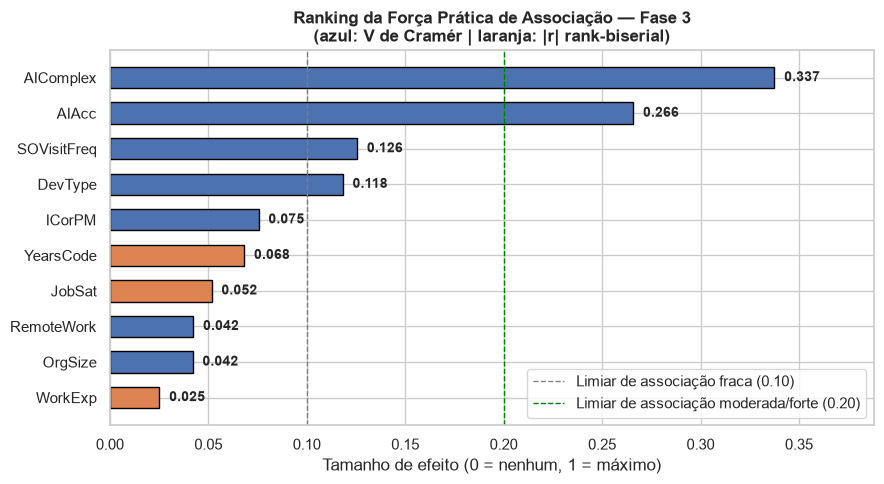

In [63]:
df_efeito = bivariate_report.sort_values("forca_efeito", ascending=True)
cores = ["#4C72B0" if t == "Qui-Quadrado" else "#DD8452" for t in df_efeito["teste"]]

plt.figure(figsize=(9, 5))
bars = plt.barh(df_efeito["variável"], df_efeito["forca_efeito"], color=cores, edgecolor="black", height=0.6)
plt.axvline(0.10, color="gray", linestyle="--", linewidth=1, label="Limiar de associação fraca (0.10)")
plt.axvline(0.20, color="green", linestyle="--", linewidth=1, label="Limiar de associação moderada/forte (0.20)")
plt.title("Ranking da Força Prática de Associação — Fase 3\n(azul: V de Cramér | laranja: |r| rank-biserial)",
          fontsize=12, fontweight="bold")
plt.xlabel("Tamanho de efeito (0 = nenhum, 1 = máximo)")
plt.legend(loc="lower right")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va="center", fontsize=10, fontweight="bold")
plt.xlim(0, max(df_efeito["forca_efeito"]) * 1.15)
plt.tight_layout()
plt.show()

### Filtro de evidências e descarte físico

Preditores com p ≥ 0.05 contra o alvo são descartados fisicamente do conjunto de preditores que avança para a Fase 4 (colinearidade). Apenas atributos estatisticamente significativos avançam.

In [64]:
SIGNIFICANT_PREDICTORS = bivariate_report.loc[bivariate_report["significativo (p<0.05)"], "variável"].tolist()
DROPPED_FASE3 = bivariate_report.loc[~bivariate_report["significativo (p<0.05)"], "variável"].tolist()
print("Preditores significativos (avançam para Fase 4):", SIGNIFICANT_PREDICTORS)
print("Preditores descartados (p >= 0.05):", DROPPED_FASE3)
significativos = SIGNIFICANT_PREDICTORS

Preditores significativos (avançam para Fase 4): ['WorkExp', 'YearsCode', 'DevType', 'OrgSize', 'AIAcc', 'AIComplex', 'JobSat', 'RemoteWork', 'ICorPM', 'SOVisitFreq']
Preditores descartados (p >= 0.05): []


### Diagnóstico de viés por subgrupo (cuidado indicado no roteiro)

Antes da aceitação de um preditor categórico como relevante, verifica-se se sua associação não decorre de um subgrupo minoritário disperso demais (contagem esperada muito baixa nalguma célula), o que infla o Qui-Quadrado artificialmente. É reportada a menor contagem esperada de cada teste categórico significativo; valores abaixo de 5 exigiriam agrupamento ou teste exato.

In [65]:
def min_expected_count(col, top_n=15):
    s = df_lab[col]
    if s.nunique() > top_n:
        top = s.value_counts().nlargest(top_n).index
        s = s.where(s.isin(top), "Outros_agrupado")
    table = pd.crosstab(s, df_lab["AIAgents_bin"])
    _, _, _, expected = stats.chi2_contingency(table)
    return expected.min()

cat_significant = [v for v in significativos if v in CATEGORICAL]
min_counts = {c: round(min_expected_count(c), 1) for c in cat_significant}
print("Menor contagem esperada por variável categórica significativa:")
pd.Series(min_counts, name="Min Expected Count").to_frame()

Menor contagem esperada por variável categórica significativa:


,Min Expected Count
DevType,85.1
OrgSize,124.6
AIAcc,33.5
AIComplex,28.7
RemoteWork,855.4
ICorPM,868.8
SOVisitFreq,156.5


**Leitura:** todas as menores contagens esperadas ficaram muito acima de 5 (mínimo de 28,7, em `AIComplex`). As premissas do Qui-Quadrado são atendidas, e o **teste exato de Fisher é dispensável**. O $V$ de Cramér acompanha o Qui-Quadrado como **medida de tamanho de efeito**, não como teste alternativo.

### Verificação da direção das hipóteses direcionais

Qui-Quadrado e Mann-Whitney bilateral só indicam se existe associação, não o sentido dela. Como H1, H2 (porte), H3, H5 e H6 preveem um **sentido**, ele é conferido explicitamente:

- **Contínuas:** sinal da correlação *rank-biserial* (positivo = adotantes com valores maiores).
- **Ordinais** (`OrgSize`, `AIAcc`, `AIComplex`, `SOVisitFreq`): correlação de Spearman entre a posição do nível na escala e o alvo (níveis fora da escala, como `'missing'` e "I don't know", são excluídos).
- **Contrastes nominais** (`RemoteWork`, `ICorPM`): diferença entre as taxas de adoção dos dois grupos citados na hipótese.

In [66]:
ORDINAL_LEVELS = {
    "OrgSize": ["Just me - I am a freelancer, sole proprietor, etc.", "Less than 20 employees",
                "20 to 99 employees", "100 to 499 employees", "500 to 999 employees",
                "1,000 to 4,999 employees", "5,000 to 9,999 employees", "10,000 or more employees"],
    "AIAcc": ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Highly trust"],
    "AIComplex": ["Very poor at handling complex tasks", "Bad at handling complex tasks",
                  "Neither good or bad at handling complex tasks",
                  "Good, but not great at handling complex tasks", "Very well at handling complex tasks"],
    "SOVisitFreq": ["Infrequently, less than once per year", "Less than once every 2 - 3 months",
                    "Less than once per month or monthly", "A few times per month or weekly",
                    "A few times per week", "Daily or almost daily", "Multiple times per day"],
}
CONTRASTES = {  # (grupo que a hipótese prevê adotar mais, grupo de comparação)
    "RemoteWork": ("Remote", "In-person"),
    "ICorPM": ("Individual contributor", "People manager"),
}
# (hipótese, variável, sentido esperado da associação com a adoção)
DIRECTION_SPEC = [
    ("H1", "WorkExp", "-"), ("H1", "YearsCode", "-"),
    ("H2", "DevType", None), ("H2", "OrgSize", "+"),
    ("H3", "AIAcc", "+"), ("H3", "AIComplex", "+"),
    ("H4", "JobSat", None),
    ("H5", "RemoteWork", "+"), ("H5", "ICorPM", "+"),
    ("H6", "SOVisitFreq", "-"),
]

direcoes = []
for h, v, esperado in DIRECTION_SPEC:
    if v in CONTINUOUS:
        medida = "r rank-biserial"
        valor = bivariate_report.loc[bivariate_report["variável"] == v, "efeito_assinado"].iloc[0]
    elif v in ORDINAL_LEVELS:
        medida = "Spearman (nível ordinal x alvo)"
        codigo = df_lab[v].map({nivel: i for i, nivel in enumerate(ORDINAL_LEVELS[v])})
        ok = codigo.notna()
        valor = stats.spearmanr(codigo[ok], df_lab.loc[ok, "AIAgents_bin"]).statistic
    elif v in CONTRASTES:
        a, b = CONTRASTES[v]
        taxas = df_lab.groupby(v)["AIAgents_bin"].mean()
        medida = f"taxa({a}) − taxa({b})"
        valor = taxas[a] - taxas[b]
    else:
        medida, valor = "—", np.nan
    if esperado is None:
        confirmado = "N.A."
    else:
        confirmado = "Sim" if np.sign(valor) == (1 if esperado == "+" else -1) else "Não"
    direcoes.append({
        "hipótese": h, "variável": v, "medida de direção": medida,
        "valor observado": round(valor, 3) if pd.notna(valor) else np.nan,
        "sentido esperado": {"+": "positivo (mais uso)", "-": "negativo (menos uso)", None: "não direcional"}[esperado],
        "sentido confirmado": confirmado,
    })

direction_report = pd.DataFrame(direcoes)
direction_report

,hipótese,variável,medida de direção,valor observado,sentido esperado,sentido confirmado
0,H1,WorkExp,r rank-biserial,-0.025,negativo (menos uso),Sim
1,H1,YearsCode,r rank-biserial,-0.068,negativo (menos uso),Sim
2,H2,DevType,—,NaN,não direcional,N.A.
3,H2,OrgSize,Spearman (nível ordinal x alvo),-0.029,positivo (mais uso),Não
4,H3,AIAcc,Spearman (nível ordinal x alvo),0.261,positivo (mais uso),Sim
5,H3,AIComplex,Spearman (nível ordinal x alvo),0.232,positivo (mais uso),Sim
6,H4,JobSat,r rank-biserial,0.052,não direcional,N.A.
7,H5,RemoteWork,taxa(Remote) − taxa(In-person),0.030,positivo (mais uso),Sim
8,H5,ICorPM,taxa(Individual contributor) − taxa(People man...,-0.114,positivo (mais uso),Não
9,H6,SOVisitFreq,Spearman (nível ordinal x alvo),-0.094,negativo (menos uso),Sim


In [67]:
# Taxas de adoção por nível, para leitura direta das associações mais relevantes
for v in ["AIAcc", "AIComplex", "SOVisitFreq", "ICorPM", "RemoteWork", "OrgSize"]:
    t = df_lab.groupby(v)["AIAgents_bin"].agg(taxa_adocao="mean", n="count")
    if v in ORDINAL_LEVELS:
        t = t.reindex(ORDINAL_LEVELS[v] + [c for c in t.index if c not in ORDINAL_LEVELS[v]])
    print(f"\n--- {v} ---")
    print(t.assign(taxa_adocao=lambda d: (100 * d["taxa_adocao"]).round(1).astype(str) + "%").to_string())


--- AIAcc ---
                           taxa_adocao     n
AIAcc                                       
Highly distrust                  13.9%  4962
Somewhat distrust                25.5%  6543
Neither trust nor distrust       35.2%  5278
Somewhat trust                   44.4%  7234
Highly trust                     65.0%   632
missing                          51.4%   105

--- AIComplex ---
                                                      taxa_adocao     n
AIComplex                                                              
Very poor at handling complex tasks                         21.6%  4682
Bad at handling complex tasks                               32.3%  5661
Neither good or bad at handling complex tasks               37.4%  3452
Good, but not great at handling complex tasks               48.2%  6131
Very well at handling complex tasks                         65.2%   905
I don't use AI tools for complex tasks / I don't know        4.5%  3833
missing                       

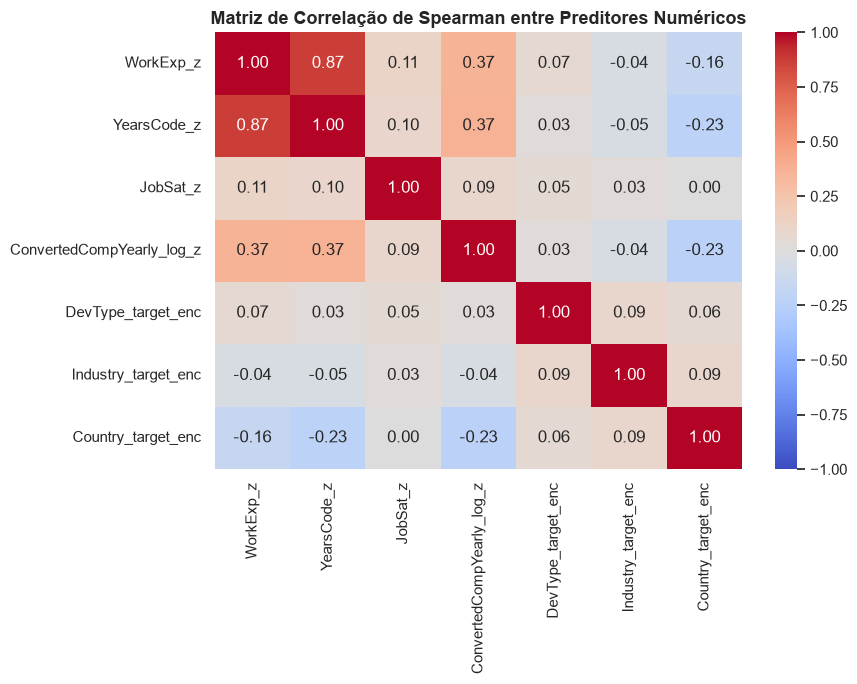

In [68]:
num_features = [f"{c}_z" for c in Z_SOURCE] + [f"{c}_target_enc" for c in HIGH_CARD]
spearman_corr = df_lab[num_features].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de Correlação de Spearman entre Preditores Numéricos", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Fase 4: Análise de Colinearidade e Multicolinearidade (Tratamento)

O Fator de Inflação da Variância (VIF) é calculado para os preditores sobreviventes da Fase 3, já projetados (dummy/target encoding da Fase 2 + Z-score). O limiar de exclusão é **VIF > 5**. Por se tratar do Caminho A, a colinearidade afeta principalmente a estabilidade de modelos lineares/logísticos; ainda assim, o VIF é tratado para garantir parcimônia.

In [69]:
def feature_columns_for(var):
    if var in ("WorkExp", "YearsCode", "JobSat"):
        return [f"{var}_z"]
    if var in HIGH_CARD:
        return [f"{var}_target_enc"]
    return [c for c in df_lab.columns if c.startswith(f"{var}_") and c in df_dummies.columns]

vif_features = []
for v in SIGNIFICANT_PREDICTORS:
    vif_features += feature_columns_for(v)
vif_features = sorted(set(vif_features))
print("Colunas do design matrix para VIF:", len(vif_features))

X_vif = df_lab[vif_features].astype(float)
X_vif = X_vif.assign(const=1.0)

Colunas do design matrix para VIF: 38


In [70]:
def compute_vif(X):
    cols = [c for c in X.columns if c != "const"]
    return pd.DataFrame({
        "variável": cols,
        "VIF": [variance_inflation_factor(X.values, X.columns.get_loc(c)) for c in cols],
    }).sort_values("VIF", ascending=False)

vif_report = compute_vif(X_vif)
vif_report

,variável,VIF
28,RemoteWork_missing,28.967236
23,OrgSize_missing,20.617369
13,ICorPM_missing,12.158095
36,WorkExp_z,5.070114
37,YearsCode_z,5.054613
3,AIAcc_Somewhat trust,2.739570
17,OrgSize_20 to 99 employees,2.266030
16,OrgSize_100 to 499 employees,2.162169
26,RemoteWork_Remote,2.120904
1,AIAcc_Neither trust nor distrust,2.110533


### Regra de corte do VIF (iterativa)

A variável com maior VIF > 5 é removida uma a uma, recalculando-se a cada rodada, até que todas as sobreviventes apresentem VIF ≤ 5. Esse procedimento evita a remoção em bloco de variáveis cuja colinearidade era causada por uma única redundante.

In [71]:
X_iter = X_vif.copy()
removed_vif = []
while True:
    rep = compute_vif(X_iter)
    worst = rep.iloc[0]
    if worst["VIF"] <= 5:
        break
    removed_vif.append({"variável": worst["variável"], "VIF_no_momento_da_remoção": round(worst["VIF"], 2)})
    X_iter = X_iter.drop(columns=[worst["variável"]])

final_vif = compute_vif(X_iter)
print("Removidas por VIF > 5:")
display(pd.DataFrame(removed_vif)) if removed_vif else print("(nenhuma)")
print("\nVIF final (todas <= 5):")
final_vif

Removidas por VIF > 5:


,variável,VIF_no_momento_da_remoção
0,RemoteWork_missing,28.97
1,OrgSize_missing,9.66
2,WorkExp_z,5.07



VIF final (todas <= 5):


,variável,VIF
3,AIAcc_Somewhat trust,2.723402
13,ICorPM_missing,2.295419
1,AIAcc_Neither trust nor distrust,2.103516
17,OrgSize_20 to 99 employees,2.079029
25,RemoteWork_Remote,2.044161
16,OrgSize_100 to 499 employees,1.999654
22,OrgSize_Less than 20 employees,1.932739
2,AIAcc_Somewhat distrust,1.887194
5,"AIComplex_Good, but not great at handling comp...",1.856008
15,"OrgSize_10,000 or more employees",1.810474


In [72]:
FINAL_FEATURES = [c for c in X_iter.columns if c != "const"]
print("Features finais pós-colinearidade:", len(FINAL_FEATURES))
FINAL_FEATURES

Features finais pós-colinearidade: 35


['AIAcc_Highly trust',
 'AIAcc_Neither trust nor distrust',
 'AIAcc_Somewhat distrust',
 'AIAcc_Somewhat trust',
 'AIAcc_missing',
 'AIComplex_Good, but not great at handling complex tasks',
 "AIComplex_I don't use AI tools for complex tasks / I don't know",
 'AIComplex_Neither good or bad at handling complex tasks',
 'AIComplex_Very poor at handling complex tasks',
 'AIComplex_Very well at handling complex tasks',
 'AIComplex_missing',
 'DevType_target_enc',
 'ICorPM_People manager',
 'ICorPM_missing',
 'JobSat_z',
 'OrgSize_10,000 or more employees',
 'OrgSize_100 to 499 employees',
 'OrgSize_20 to 99 employees',
 'OrgSize_5,000 to 9,999 employees',
 'OrgSize_500 to 999 employees',
 'OrgSize_I don’t know',
 'OrgSize_Just me - I am a freelancer, sole proprietor, etc.',
 'OrgSize_Less than 20 employees',
 'RemoteWork_Hybrid (some remote, leans heavy to in-person)',
 'RemoteWork_In-person',
 'RemoteWork_Remote',
 'RemoteWork_Your choice (very flexible, you can come in when you want or j

## Fase 5: Conexão com Machine Learning e Explicabilidade

Para cada preditor contínuo sobrevivente, é ajustada uma curva de suavização local (**LOESS**) contra `AIAgents_bin`, permitindo inspecionar linearidade/monotonicidade e justificar a família de modelo a recomendar nas próximas etapas de modelagem preditiva.

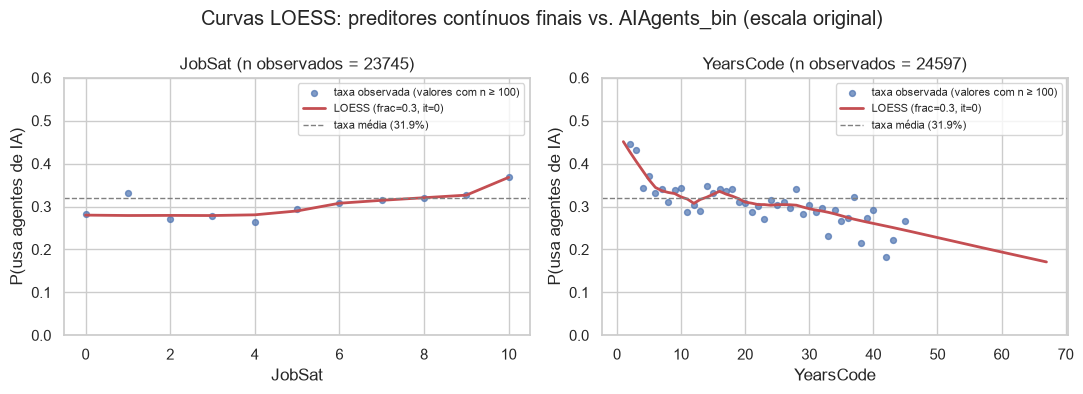

In [73]:
# LOESS sobre os valores OBSERVADOS (isBAD == False): os valores imputados pela mediana formariam
# um pico artificial num único ponto do eixo x. it=0 desliga as iterações robustas do lowess, que,
# com alvo binário, tratam a classe minoritária (1) como outlier e puxam a curva para baixo.
continuous_final = [f[:-2] for f in FINAL_FEATURES if f.endswith("_z")]
taxa_base = df_lab["AIAgents_bin"].mean()

fig, axes = plt.subplots(1, len(continuous_final), figsize=(5.5 * len(continuous_final), 4), squeeze=False)
for ax, col in zip(axes[0], continuous_final):
    obs = df_lab[~df_lab[f"{col}_isBAD"]]
    x = obs[col].values.astype(float)
    y = obs["AIAgents_bin"].values.astype(float)
    smoothed = lowess(y, x, frac=0.3, it=0, return_sorted=True)
    taxa_por_valor = obs.groupby(col)["AIAgents_bin"].agg(["mean", "count"])
    taxa_por_valor = taxa_por_valor[taxa_por_valor["count"] >= 100]
    ax.scatter(taxa_por_valor.index, taxa_por_valor["mean"], s=18, color="#4C72B0", alpha=0.7,
               label="taxa observada (valores com n ≥ 100)")
    ax.plot(smoothed[:, 0], smoothed[:, 1], color="#C44E52", linewidth=2, label="LOESS (frac=0.3, it=0)")
    ax.axhline(taxa_base, color="gray", linestyle="--", linewidth=1, label=f"taxa média ({taxa_base:.1%})")
    ax.set_title(f"{col} (n observados = {len(obs)})")
    ax.set_xlabel(col)
    ax.set_ylabel("P(usa agentes de IA)")
    ax.set_ylim(0, 0.6)
    ax.legend(fontsize=8)
plt.suptitle("Curvas LOESS: preditores contínuos finais vs. AIAgents_bin (escala original)")
plt.tight_layout()
plt.show()

**Diagnóstico Científico LOESS:**

- **`YearsCode`:** relação **monotônica decrescente, mas não-linear**. A adoção cai rapidamente nos primeiros ~5 anos de programação (de ~45% para ~33%), forma um **platô** entre ~5 e ~28 anos (próximo da média de 31,9%) e volta a cair depois disso (~20–25% acima de 40 anos; a cauda acima de 45 anos tem poucos casos e deve ser lida com cautela). O sentido confirma H1, embora o efeito global seja pequeno ($r = -0{,}068$).
- **`JobSat`:** relação **monotônica crescente, mas não-linear**. A adoção fica estável (~28%) entre as notas 0 e 4 e sobe gradualmente a partir de 5, chegando a ~37% na nota 10.

**Implicação para a modelagem:** não há comportamento não-monotônico (inversão de sentido), mas há **platôs e mudanças de inclinação** (limiares), que um termo linear único não captura. Isso favorece modelos baseados em árvores, que aprendem cortes por limiar naturalmente — **Árvore de Decisão** como modelo de base e **Random Forest / Gradient Boosting** como segundo modelo. Pesa também a favor das árvores o fato de a maior parte da matriz final ser composta de dummies e de um *target encoding*, em que interações entre variáveis são plausíveis. Uma regressão logística com termos não-lineares (ex.: *splines*) seria uma alternativa interpretável viável, já que as relações são monotônicas.

> **Nota técnica:** as curvas usam apenas valores observados (sem os imputados pela mediana, que criariam um pico artificial) e `it=0` no `lowess` — as iterações robustas padrão tratam a classe minoritária (1) como *outlier* em alvos binários e subestimam a probabilidade.

### Fechamento Metodológico Obrigatório do Bloco A

Consolidação formal de quais hipóteses da Fase 0 resistiram à auditoria empírica e apresentação da Trilha de Auditoria (*Audit Trail*) contínua.

In [74]:
HYPOTHESIS_TEXT = {
    "H1": "Experiência (WorkExp/YearsCode) associada a MENOR uso de agentes de IA",
    "H2": "Cargo (DevType) e porte (OrgSize, empresas maiores => mais uso) associados ao uso",
    "H3": "Confiança (AIAcc) e percepção em tarefas complexas (AIComplex) associadas a MAIOR uso",
    "H4": "Satisfação no cargo (JobSat) associada ao uso (não direcional)",
    "H5": "Trabalho remoto e contribuidores individuais (ICorPM) adotam MAIS",
    "H6": "Maior frequência de visita ao SO associada a MENOR uso",
}
EFEITO_MIN = 0.10  # abaixo disso o efeito é desprezível/fraco (convenção de Cohen para V e |r|)

removidas_vif = {v for v in SIGNIFICANT_PREDICTORS
                 if not any(f == f"{v}_z" or f == f"{v}_target_enc" or f.startswith(f"{v}_") for f in FINAL_FEATURES)}

quadro_hipoteses = []
for h, texto in HYPOTHESIS_TEXT.items():
    testes = bivariate_report[bivariate_report["hipótese"] == h]
    direcoes = direction_report[(direction_report["hipótese"] == h) & (direction_report["sentido esperado"] != "não direcional")]
    nao_sig = testes.loc[~testes["significativo (p<0.05)"], "variável"].tolist()
    contrarias = direcoes.loc[direcoes["sentido confirmado"] == "Não", "variável"].tolist()
    fracas = testes.loc[testes["forca_efeito"] < EFEITO_MIN, "variável"].tolist()
    apoiam = [v for v in testes["variável"] if v not in nao_sig + contrarias]

    if not apoiam:
        decisao = "REFUTADA"
    elif nao_sig or contrarias:
        motivos = ([f"sem significância: {', '.join(nao_sig)}"] if nao_sig else []) + \
                  ([f"direção contrária: {', '.join(contrarias)}"] if contrarias else [])
        decisao = f"PARCIAL ({'; '.join(motivos)})"
    elif fracas:
        decisao = f"MANTIDA COM RESSALVA (efeito < {EFEITO_MIN} em: {', '.join(fracas)})"
    else:
        decisao = "MANTIDA"

    resultado = "; ".join(
        f"{r['variável']}: p={r['p_valor']:.1e}, {r['tamanho_efeito']}" for _, r in testes.iterrows()
    )
    obs = [f"{v} removida por VIF > 5 (redundante)" for v in testes["variável"] if v in removidas_vif]
    quadro_hipoteses.append({
        "ID": h, "Hipótese": texto, "Teste(s)": ", ".join(sorted(set(testes["teste"]))),
        "Resultado": resultado, "Decisão": decisao, "Observação": "; ".join(obs),
    })

df_quadro_hipoteses = pd.DataFrame(quadro_hipoteses)
with pd.option_context("display.max_colwidth", None):
    display(df_quadro_hipoteses)

,ID,Hipótese,Teste(s),Resultado,Decisão,Observação
0,H1,Experiência (WorkExp/YearsCode) associada a MENOR uso de agentes de IA,Mann-Whitney U,"WorkExp: p=1.4e-03, r rank-biserial = -0.025; YearsCode: p=4.6e-18, r rank-biserial = -0.068","MANTIDA COM RESSALVA (efeito < 0.1 em: WorkExp, YearsCode)",WorkExp removida por VIF > 5 (redundante)
1,H2,"Cargo (DevType) e porte (OrgSize, empresas maiores => mais uso) associados ao uso",Qui-Quadrado,"DevType: p=1.4e-64, V de Cramér = 0.118; OrgSize: p=1.6e-06, V de Cramér = 0.042",PARCIAL (direção contrária: OrgSize),
2,H3,Confiança (AIAcc) e percepção em tarefas complexas (AIComplex) associadas a MAIOR uso,Qui-Quadrado,"AIAcc: p=0.0e+00, V de Cramér = 0.266; AIComplex: p=0.0e+00, V de Cramér = 0.337",MANTIDA,
3,H4,Satisfação no cargo (JobSat) associada ao uso (não direcional),Mann-Whitney U,"JobSat: p=2.3e-11, r rank-biserial = +0.052",MANTIDA COM RESSALVA (efeito < 0.1 em: JobSat),
4,H5,Trabalho remoto e contribuidores individuais (ICorPM) adotam MAIS,Qui-Quadrado,"RemoteWork: p=2.0e-08, V de Cramér = 0.042; ICorPM: p=2.3e-31, V de Cramér = 0.075",PARCIAL (direção contrária: ICorPM),
5,H6,Maior frequência de visita ao SO associada a MENOR uso,Qui-Quadrado,"SOVisitFreq: p=3.2e-80, V de Cramér = 0.126",MANTIDA,


**Leitura do quadro de hipóteses:**

- **H3 (confiança e percepção em tarefas complexas) é a hipótese mais forte da base:** a adoção sobe de forma monotônica de 13,9% ("Highly distrust") para 65,0% ("Highly trust") em `AIAcc`, e de 21,6% para 65,2% em `AIComplex`.
- **H6 confirmada:** quem visita o Stack Overflow várias vezes por dia adota menos que quem o visita raramente (efeito de substituição parcial, $V = 0{,}126$).
- **H1 e H4 mantidas com ressalva:** o sentido é o previsto (H1) e a associação é significativa, mas o tamanho de efeito é desprezível ($|r| < 0{,}10$); a significância decorre do tamanho da amostra.
- **H2 parcial:** `DevType` tem associação fraca, mas relevante ($V = 0{,}118$); já `OrgSize` tem efeito desprezível e **no sentido oposto** ao previsto (empresas maiores adotam ligeiramente menos).
- **H5 parcial:** trabalho remoto adota um pouco mais que presencial, como previsto, mas **gestores de pessoas adotam mais que contribuidores individuais** (≈41,7% vs. ≈30,3%), contrariando a hipótese.

As hipóteses não foram reformuladas após a observação dos dados, para evitar *HARKing* (formular hipóteses depois de conhecer os resultados); as divergências ficam registradas como achados.

In [75]:
# Complementa a trilha iniciada na Fase 0 (registrar_auditoria) — sem reiniciar a lista,
# para preservar os registros das Fases 0, 1 e 2.
for v in DROPPED_FASE3:
    row = bivariate_report[bivariate_report["variável"] == v].iloc[0]
    registrar_auditoria("Fase 3", v, "Descartada", f"{row['teste']}: p={row['p_valor']:.3g} (>= 0.05, sem significância).")

for r in removed_vif:
    registrar_auditoria("Fase 4", r["variável"], "Coluna removida (VIF > 5)",
                        f"VIF = {r['VIF_no_momento_da_remoção']} no momento da remoção (procedimento iterativo).")

for v in SIGNIFICANT_PREDICTORS:
    if v in removidas_vif:
        registrar_auditoria("Fase 4", v, "Descartada (variável inteira)",
                            "Todas as suas colunas codificadas foram removidas por VIF > 5.")
    else:
        registrar_auditoria("Fase 5", v, "Mantida (sobrevivente final)",
                            "Significativa na Fase 3 e com VIF <= 5 na Fase 4.")

audit_trail_df = pd.DataFrame(audit_trail)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 90):
    display(audit_trail_df)

,Fase,Variável,Status,Justificativa
0,Fase 0,AISelect,Descartada (preditor),Proxy quase direta do alvo (vazamento/tautologia). Guardada em df_outcomes.
1,Fase 0,ResponseId,Mantida (não-preditora),"Chave primária sequencial de controle operacional, sem poder explicativo."
2,Fase 1,WorkExp,Outlier extremo -> NA,"18 valores fora de [-37.0, 61.0] (3x IQR) convertidos em NA."
3,Fase 1,YearsCode,Outlier extremo -> NA,"21 valores fora de [-39.0, 73.0] (3x IQR) convertidos em NA."
4,Fase 1,JobSat,Outlier extremo -> NA,"0 valores fora de [0.0, 14.0] (3x IQR) convertidos em NA."
5,Fase 1,ConvertedCompYearly,Outlier extremo -> NA,"292 valores fora de [-204985.0, 370789.5] (3x IQR) convertidos em NA."
6,Fase 1,Age/EdLevel/Employment (linhas),659 linhas removidas,"Remoção de casos com NAs em colunas de perda irrelevante (< 2%, total: 1.76%)."
7,Fase 1,WorkExp,isBAD (imputado 10.0),5.24% nulos imputados pela mediana; coluna indicadora WorkExp_isBAD criada.
8,Fase 1,YearsCode,isBAD (imputado 15.0),9.48% nulos imputados pela mediana; coluna indicadora YearsCode_isBAD criada.
9,Fase 1,JobSat,isBAD (imputado 8.0),27.61% nulos imputados pela mediana; coluna indicadora JobSat_isBAD criada.


In [76]:
n_populacao = int((df_raw["MainBranch"] == "I am a developer by profession").sum())
variaveis_finais = [v for v in SIGNIFICANT_PREDICTORS if v not in removidas_vif]

print("=== FECHAMENTO NUMÉRICO DO PIPELINE (ETAPA 1) ===")
print(f"Base bruta original: {len(df_raw)} linhas x {len(raw_header.columns)} colunas")
print(f"População de estudo (devs profissionais, recorte de escopo): {n_populacao} linhas")
print(f"Após remoção de linhas com NA em variáveis com < 2% de ausência (Fase 1): {len(df)} linhas")
print(f"Registros rotulados válidos (df_lab): {len(df_lab)} linhas")
print(f"Colunas selecionadas para o estudo: {len(COLS)} (inclui ResponseId e MainBranch)")
print("Descartadas na Fase 0: AISelect (vazamento); ResponseId mantida apenas como chave")
print(f"Colunas codificadas removidas por VIF > 5 (Fase 4): {len(removed_vif)} -> {[r['variável'] for r in removed_vif]}")
print(f"Variáveis originais eliminadas por inteiro na Fase 4: {sorted(removidas_vif)}")
print(f"Preditores finais: {len(variaveis_finais)} variáveis originais -> {len(FINAL_FEATURES)} colunas codificadas")
print("  ", variaveis_finais)

=== FECHAMENTO NUMÉRICO DO PIPELINE (ETAPA 1) ===
Base bruta original: 49191 linhas x 172 colunas
População de estudo (devs profissionais, recorte de escopo): 37467 linhas
Após remoção de linhas com NA em variáveis com < 2% de ausência (Fase 1): 36808 linhas
Registros rotulados válidos (df_lab): 24754 linhas
Colunas selecionadas para o estudo: 22 (inclui ResponseId e MainBranch)
Descartadas na Fase 0: AISelect (vazamento); ResponseId mantida apenas como chave
Colunas codificadas removidas por VIF > 5 (Fase 4): 3 -> ['RemoteWork_missing', 'OrgSize_missing', 'WorkExp_z']
Variáveis originais eliminadas por inteiro na Fase 4: ['WorkExp']
Preditores finais: 9 variáveis originais -> 35 colunas codificadas
   ['YearsCode', 'DevType', 'OrgSize', 'AIAcc', 'AIComplex', 'JobSat', 'RemoteWork', 'ICorPM', 'SOVisitFreq']


---
# Bloco B — Modelagem Preditiva e Avaliação Rigorosa

O Bloco A concluiu a fase exploratória e entregou a base condicionada, auditada e com explicabilidade preliminar. Agora, no Bloco B, iniciamos a etapa de modelagem preditiva, estabelecendo a formulação formal do problema, a métrica de negócio, o baseline de comparação e o protocolo rigoroso de particionamento para blindagem contra vazamento de dados (*data leakage*).

## Fase 6 — Formulação do problema, métrica e baseline (Entrega 1)

Nesta fase definimos formalmente a tarefa de aprendizado de máquina, alinhamos o momento da tomada de decisão no negócio para prevenir vazamento de alvo (*target leakage*), estabelecemos a matriz de custo de erros e definimos o baseline ingênuo de referência.

### 6.1 Unidade de observação, tarefa e momento da decisão

- **Tipo de tarefa:** **Classificação Binária Supervisionada** (Caminho A).
- **Variável-alvo:** `AIAgents_bin` ($1$ = Desenvolvedor utiliza agentes de IA no trabalho; $0$ = Desenvolvedor não utiliza agentes ou utiliza exclusivamente ferramentas de autocompletar).
- **Unidade de observação:** Cada linha representa um desenvolvedor profissional individual.
- **Momento da decisão no negócio:** A previsão do modelo será utilizada no início de ciclos corporativos de planejamento de TI ou lançamento de ferramentas para identificar quais desenvolvedores e equipes têm alta probabilidade de adotar agentes de IA. Isso orienta a distribuição de licenças empresariais, programas piloto e treinamentos de capacitação técnica de forma proativa.
- **Prevenção de Target Leakage:** `AISelect` (proxy quase direta do alvo) foi excluída na Fase 0. Os demais preditores refletem perfil estrutural, senioridade, tamanho de empresa, arranjo de trabalho e percepções sobre IA, todos obtíveis por questionário antes da decisão.
- **Risco remanescente (causalidade reversa):** `AIAcc` e `AIComplex` são percepções que podem ser, em parte, *consequência* do uso de agentes (quem usa avalia melhor a IA). O nível `AIComplex = "I don't use AI tools for complex tasks"` tem taxa de adoção de apenas ~4,5%, aproximando-se de uma descrição do próprio comportamento. Recomenda-se, nas próximas fases, comparar o desempenho com e sem esses dois preditores (análise de sensibilidade).

### 6.2 Análise de custo dos erros e escolha da métrica principal

Em um cenário de planejamento tecnológico corporativo:
- **Falso Positivo (FP):** O modelo prevê que o desenvolvedor adotará agentes, mas ele não adota.  
  *Custo:* Baixo a moderado (custo de alocação de licença ou convite para workshop que não é plenamente aproveitado).
- **Falso Negativo (FN):** O modelo prevê que o desenvolvedor não adotará, e a organização deixa de equipá-lo e capacitá-lo com agentes autônomos.  
  *Custo:* Alto (perda substancial de ganho de produtividade competitiva e risco de defasagem técnica do profissional).

**Métrica Principal Escolhida:** **F1-Score da Classe Positiva (Adotantes)**.  
Como a classe positiva representa aproximadamente 31,9% dos respondentes válidos (desbalanceamento moderado de ~2,1:1), a acurácia convencional é uma métrica enganosa: um classificador ingênuo que aposte apenas na maioria obteria 68,1% de acurácia com utilidade nula para o negócio. O **F1-Score da classe positiva** harmoniza Precisão e Recall, garantindo que o modelo capture o máximo de adotantes potenciais (Recall alto) sem produzir um número inaceitável de alarmes falsos (Precisão controlada).

**Métricas Secundárias de Diagnóstico:**  
- **PR-AUC (Precision-Recall Area Under Curve):** Curva recomendada para classes minoritárias.
- **Balanced Accuracy:** Média aritmética da sensibilidade de cada classe.
- **Acurácia Global:** Reportada apenas como conferência de sanidade.

**Critério de Sucesso do Negócio:**  
O modelo de aprendizado de máquina deve superar expressivamente **os dois** baselines ingênuos em F1-Score da classe positiva: o majoritário ($F1 = 0$) e, principalmente, o estratificado aleatório ($F1 \approx 0{,}32$, igual à prevalência da classe positiva). Meta: $F1 > 0{,}50$ na validação cruzada do treino.

### 6.3 Baseline de Referência Ingênuo (`DummyClassifier`)

Conforme exigido pelo protocolo metodológico, todo modelo preditivo deve ser contrastado contra uma referência ingênua que não aprende regras dos dados:
1. `DummyClassifier(strategy="most_frequent")`: Sempre prevê a classe majoritária ($0$ = Não Adotante).
2. `DummyClassifier(strategy="stratified")`: Prevê classes aleatoriamente respeitando a proporção da base.

Para que a comparação seja justa, os baselines são avaliados **sob o mesmo protocolo dos modelos** (validação cruzada estratificada no treino, Seção 7.4), e não sobre a base inteira. Abaixo, apenas montamos a base de modelagem.

In [77]:
# Base de modelagem: as MESMAS linhas de df_lab (rotuladas, após a regra dos 2%), mas com os valores
# ANTERIORES a qualquer etapa que aprende com os dados (cercas de outlier, medianas, z-score, target
# encoding). Esses passos são refeitos dentro do Pipeline da Fase 7, ajustado só no treino.
# A seleção de variáveis vem das Fases 3-4 (FINAL_FEATURES).
NUM_MODEL = [v for v in CONTINUOUS if f"{v}_z" in FINAL_FEATURES]
TE_MODEL = [v for v in HIGH_CARD if f"{v}_target_enc" in FINAL_FEATURES]
DUMMY_MODEL = [c for c in FINAL_FEATURES if c in df_dummies.columns]
OHE_SOURCE = [v for v in LOW_CARD if any(c.startswith(f"{v}_") for c in DUMMY_MODEL)]

base_modelagem = df_pre_aprendizado.set_index("ResponseId").loc[df_lab["ResponseId"]]
X_modelagem = base_modelagem[NUM_MODEL + TE_MODEL + OHE_SOURCE].reset_index(drop=True)
y_modelagem = df_lab["AIAgents_bin"].reset_index(drop=True)

print("Numéricas (outlier -> isBAD/mediana -> z-score):", NUM_MODEL)
print("Alta cardinalidade (target encoding por dobras):", TE_MODEL)
print("Baixa cardinalidade (dummies aprovadas nas Fases 3-4):", OHE_SOURCE, f"-> {len(DUMMY_MODEL)} colunas")
print(f"\nBase de Modelagem pronta: {X_modelagem.shape[0]} instâncias x {X_modelagem.shape[1]} variáveis brutas")
print(f"Distribuição real do alvo: Classe 0 = {(y_modelagem==0).mean():.1%}, Classe 1 = {(y_modelagem==1).mean():.1%}")
print("\nNAs ainda presentes (serão tratados dentro do Pipeline):")
X_modelagem.isna().sum()[lambda s: s > 0]

Numéricas (outlier -> isBAD/mediana -> z-score): ['YearsCode', 'JobSat']
Alta cardinalidade (target encoding por dobras): ['DevType']
Baixa cardinalidade (dummies aprovadas nas Fases 3-4): ['OrgSize', 'ICorPM', 'RemoteWork', 'SOVisitFreq', 'AIAcc', 'AIComplex'] -> 32 colunas

Base de Modelagem pronta: 24754 instâncias x 9 variáveis brutas
Distribuição real do alvo: Classe 0 = 68.1%, Classe 1 = 31.9%

NAs ainda presentes (serão tratados dentro do Pipeline):


YearsCode       148
JobSat         1009
OrgSize        3494
ICorPM         3861
RemoteWork     3615
SOVisitFreq     737
AIAcc           105
AIComplex        90
dtype: int64

## Fase 7 — Particionamento e prevenção de vazamento (Entrega 1)

Seguindo a regra de ouro da Ciência de Dados:
> *"Tudo o que aprende algo com os dados (médias, medianas, escalas, encodings, pesos e hiperparâmetros) deve ser ajustado exclusivamente no conjunto de treino e depois aplicado ao conjunto de teste."*

### 7.1 Separação do Conjunto de Teste (Holdout Estratificado)

- **Proporção:** 80% Treino e 20% Teste.
- **Estratificação:** `stratify=y_modelagem`, garantindo que a proporção exata de adotantes de IA (~31,9%) seja idêntica nas duas partições.
- **Semente Fixa:** `random_state=42`, garantindo reprodutibilidade científica.
- **Particionamento sobre dados brutos:** o *split* é feito **antes** de qualquer passo que aprende com os dados; por isso a base de modelagem ainda contém NAs e categorias em texto.
- **Lacramento do Teste:** O conjunto de teste é isolado e **não será tocado** até a Fase 12 (Avaliação Final Única).

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X_modelagem,
    y_modelagem,
    test_size=0.20,
    random_state=RNG_SEED,
    stratify=y_modelagem
)

print(f"Conjunto de Treino: {X_train.shape[0]} observações ({X_train.shape[0]/len(X_modelagem):.1%})")
print(f"Conjunto de Teste (Lacrado até Fase 12): {X_test.shape[0]} observações ({X_test.shape[0]/len(X_modelagem):.1%})")

proporcao_treino = y_train.value_counts(normalize=True).to_dict()
proporcao_teste = y_test.value_counts(normalize=True).to_dict()

df_estratificacao = pd.DataFrame({
    "Partição": ["Treino (80%)", "Teste (20%)", "Base Completa (100%)"],
    "Nº Amostras": [len(y_train), len(y_test), len(y_modelagem)],
    "% Classe 0 (Não Adotante)": [
        f"{proporcao_treino[0]:.2%}", f"{proporcao_teste[0]:.2%}", f"{(y_modelagem==0).mean():.2%}"
    ],
    "% Classe 1 (Adotante)": [
        f"{proporcao_treino[1]:.2%}", f"{proporcao_teste[1]:.2%}", f"{(y_modelagem==1).mean():.2%}"
    ]
})

print("\nVerificação da Estratificação de Classes:")
df_estratificacao

Conjunto de Treino: 19803 observações (80.0%)
Conjunto de Teste (Lacrado até Fase 12): 4951 observações (20.0%)

Verificação da Estratificação de Classes:


,Partição,Nº Amostras,% Classe 0 (Não Adotante),% Classe 1 (Adotante)
0,Treino (80%),19803,68.13%,31.87%
1,Teste (20%),4951,68.13%,31.87%
2,Base Completa (100%),24754,68.13%,31.87%


### 7.2 Esquema de Validação Cruzada no Treino

Para ajustar hiperparâmetros e selecionar modelos sem contaminar o teste, configuramos o objeto de validação cruzada:
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` — mantém a mesma proporção da classe positiva (~31,9%) em cada dobra.
- **Verificação de casos especiais:** `GroupKFold` não se aplica porque cada linha possui um `ResponseId` único (sem múltiplos registros do mesmo indivíduo), e `TimeSeriesSplit` também não se aplica por se tratar de um corte transversal de 2024, sem ordem temporal.
- **Pré-processamento dentro das dobras:** como o pré-processamento é um passo do `Pipeline`, a validação cruzada o reajusta em cada dobra de treino, sem enxergar a dobra de validação.
- **Pareamento entre modelos:** Este mesmo objeto de validação cruzada será compartilhado pelos modelos comparados para garantir avaliação estritamente pareada (mesmas dobras e mesmos dados).

In [79]:
cv_esquema = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)

print("Esquema de Validação Cruzada configurado com sucesso:")
print(f"  - Tipo: StratifiedKFold")
print(f"  - Número de Folds: {cv_esquema.get_n_splits()}")
print(f"  - Embaralhamento prévio (shuffle): {cv_esquema.shuffle}")
print(f"  - Semente de controle: {cv_esquema.random_state}")

fold_stats = []
for fold_idx, (idx_tr, idx_val) in enumerate(cv_esquema.split(X_train, y_train), 1):
    y_tr_fold = y_train.iloc[idx_tr]
    y_val_fold = y_train.iloc[idx_val]
    fold_stats.append({
        "Fold": f"Dobra {fold_idx}",
        "Amostras Treino": len(y_tr_fold),
        "Amostras Validação": len(y_val_fold),
        "% Positivos Validação": f"{y_val_fold.mean():.2%}"
    })

pd.DataFrame(fold_stats)

Esquema de Validação Cruzada configurado com sucesso:
  - Tipo: StratifiedKFold
  - Número de Folds: 5
  - Embaralhamento prévio (shuffle): True
  - Semente de controle: 42


,Fold,Amostras Treino,Amostras Validação,% Positivos Validação
0,Dobra 1,15842,3961,31.86%
1,Dobra 2,15842,3961,31.86%
2,Dobra 3,15842,3961,31.89%
3,Dobra 4,15843,3960,31.87%
4,Dobra 5,15843,3960,31.87%


### 7.3 Pipeline de pré-processamento ajustado somente no treino

Todo passo que **aprende parâmetros com os dados** passa a ser um estágio de um `ColumnTransformer`, ajustado apenas no treino (e, na validação cruzada, apenas na dobra de treino):

| Bloco | Passos | O que é aprendido |
|---|---|---|
| Numéricas (`YearsCode`, `JobSat`) | outlier extremo (3×IQR) → NA; imputação pela mediana; z-score | cercas de Tukey, medianas, média e desvio-padrão |
| Flags isBAD | outlier extremo → NA; indicador de ausência | cercas de Tukey |
| `DevType` | NA → `'missing'`; *target encoding* com suavização $m=10$ | taxa de adoção por categoria, por dobras (*cross-fitting*) |
| Demais categóricas | NA → `'missing'`; dummies aprovadas nas Fases 3–4 | nada (lista de colunas fixa, vinda da AED) |

O `TargetEncoder` do scikit-learn usa *cross-fitting* no `fit_transform`: cada linha do treino é codificada com estatísticas calculadas **sem** a própria dobra, o que evita que o rótulo da linha vaze para o seu próprio atributo.

In [80]:
class OutlierExtremoParaNA(BaseEstimator, TransformerMixin):
    """Cercas de Tukey (k x IQR) aprendidas no treino; valores fora delas viram NaN (tratados depois pelo isBAD)."""
    def __init__(self, k=3.0):
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.limite_inf_, self.limite_sup_ = q1 - self.k * iqr, q3 + self.k * iqr
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_).astype(float)
        return X.mask((X < self.limite_inf_) | (X > self.limite_sup_))

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


class DummiesSelecionadas(BaseEstimator, TransformerMixin):
    """Reproduz o one-hot da Fase 2 (NA -> 'missing') mantendo apenas as colunas aprovadas nas Fases 3-4.
    Não aprende nada com os dados; categorias inéditas no teste viram linha de zeros."""
    def __init__(self, colunas):
        self.colunas = colunas

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(pd.DataFrame(X).columns, dtype=object)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).astype(object).fillna("missing")
        dummies = pd.get_dummies(X, prefix=list(X.columns)).astype(float)
        return dummies.reindex(columns=self.colunas, fill_value=0.0)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas, dtype=object)


def construir_target_encoder():
    # A partir do scikit-learn 1.9, o embaralhamento das dobras é passado via objeto de CV
    # (shuffle/random_state no próprio TargetEncoder foram descontinuados).
    from sklearn import __version__ as versao_sklearn
    if tuple(int(p) for p in versao_sklearn.split(".")[:2]) >= (1, 9):
        cv_te = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
        return TargetEncoder(target_type="binary", smooth=10.0, cv=cv_te)
    return TargetEncoder(target_type="binary", smooth=10.0, cv=5, shuffle=True, random_state=RNG_SEED)


def construir_preprocessador():
    return ColumnTransformer([
        ("num", Pipeline([
            ("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
            ("mediana", SimpleImputer(strategy="median")),
            ("zscore", StandardScaler()),
        ]), NUM_MODEL),
        ("isbad", Pipeline([
            ("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
            ("flag", MissingIndicator(features="all")),
        ]), NUM_MODEL),
        ("target_enc", Pipeline([
            ("missing", SimpleImputer(strategy="constant", fill_value="missing")),
            ("te", construir_target_encoder()),
        ]), TE_MODEL),
        ("dummies", DummiesSelecionadas(DUMMY_MODEL), OHE_SOURCE),
    ], verbose_feature_names_out=True).set_output(transform="pandas")


preprocessador = construir_preprocessador()
Xt_train = preprocessador.fit_transform(X_train, y_train).astype(float)  # fit_transform => cross-fitting no TE
print(f"Matriz de treino transformada: {Xt_train.shape[0]} linhas x {Xt_train.shape[1]} colunas, "
      f"NAs restantes = {int(Xt_train.isna().sum().sum())}")

num = preprocessador.named_transformers_["num"]
te = preprocessador.named_transformers_["target_enc"].named_steps["te"]
pd.DataFrame({
    "limite_sup (3xIQR)": num.named_steps["outlier_para_na"].limite_sup_.values,
    "mediana (treino)": num.named_steps["mediana"].statistics_,
    "média z-score (treino)": num.named_steps["zscore"].mean_,
    "dp z-score (treino)": num.named_steps["zscore"].scale_,
    "mediana (AED, base inteira)": [isbad_report[[r["variável"] for r in isbad_report].index(v)]["valor de imputação (mediana)"] for v in NUM_MODEL],
}, index=NUM_MODEL).round(3)

Matriz de treino transformada: 19803 linhas x 37 colunas, NAs restantes = 0


,limite_sup (3xIQR),mediana (treino),média z-score (treino),dp z-score (treino),"mediana (AED, base inteira)"
YearsCode,70.0,15.0,18.015,10.980,15.0
JobSat,14.0,8.0,7.252,1.943,8.0


In [81]:
print(f"Target encoding de DevType aprendido só no treino: média global = {te.target_mean_:.4f}, "
      f"{len(te.categories_[0])} categorias")

# Auditoria de colinearidade da matriz final de TREINO (inclui as flags isBAD, que não estavam na Fase 4)
X_vif_treino = Xt_train.assign(const=1.0)
vif_treino = compute_vif(X_vif_treino)
print(f"VIF máximo na matriz de treino: {vif_treino['VIF'].max():.2f}")
vif_treino.head(5)

Target encoding de DevType aprendido só no treino: média global = 0.3187, 32 categorias
VIF máximo na matriz de treino: 2.72


,variável,VIF
8,dummies__AIAcc_Somewhat trust,2.721205
17,dummies__ICorPM_missing,2.293591
20,dummies__OrgSize_20 to 99 employees,2.104979
6,dummies__AIAcc_Neither trust nor distrust,2.092452
28,dummies__RemoteWork_Remote,2.040110


### 7.4 Baselines avaliados sob o protocolo (validação cruzada no treino)

Os `DummyClassifier` são encaixados no mesmo `Pipeline` (pré-processamento + modelo) e avaliados com o mesmo `cv_esquema` que será usado pelos modelos, garantindo comparação pareada. O conjunto de teste não é usado.

In [82]:
scoring = {
    "F1 (classe 1)": "f1",
    "PR-AUC": "average_precision",
    "Balanced Accuracy": "balanced_accuracy",
    "Acurácia": "accuracy",
    "Precisão (classe 1)": make_scorer(precision_score, zero_division=0),
    "Recall (classe 1)": "recall",
}

linhas_baseline = []
for nome, estrategia in [("Dummy (Mais Frequente)", "most_frequent"), ("Dummy (Estratificado Aleatório)", "stratified")]:
    pipe = Pipeline([("prep", construir_preprocessador()),
                     ("modelo", DummyClassifier(strategy=estrategia, random_state=RNG_SEED))])
    res = cross_validate(pipe, X_train, y_train, cv=cv_esquema, scoring=scoring)
    linha = {"Modelo Baseline": nome}
    for m in scoring:
        linha[m] = f"{res[f'test_{m}'].mean():.3f} ± {res[f'test_{m}'].std():.3f}"
    linhas_baseline.append(linha)

tabela_baseline = pd.DataFrame(linhas_baseline).set_index("Modelo Baseline")
print("Baselines ingênuos — média ± desvio-padrão nas 5 dobras de validação do treino:")
tabela_baseline

Baselines ingênuos — média ± desvio-padrão nas 5 dobras de validação do treino:


,F1 (classe 1),PR-AUC,Balanced Accuracy,Acurácia,Precisão (classe 1),Recall (classe 1)
Modelo Baseline,,,,,,
Dummy (Mais Frequente),0.000 ± 0.000,0.319 ± 0.000,0.500 ± 0.000,0.681 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Dummy (Estratificado Aleatório),0.322 ± 0.009,0.320 ± 0.003,0.503 ± 0.007,0.570 ± 0.006,0.323 ± 0.009,0.320 ± 0.009


### 7.5 Checklist anti-vazamento e risco residual

| Item | Situação |
|---|---|
| Teste separado antes de qualquer passo que aprende com os dados | ✔ (Seção 7.1, sobre dados brutos) |
| Cercas de outlier, medianas, z-score e flags isBAD ajustados só no treino | ✔ (Pipeline, Seção 7.3) |
| *Target encoding* por dobras (*cross-fitting*) | ✔ (`TargetEncoder`, `cv=5`) |
| Pré-processamento reajustado em cada dobra da validação cruzada | ✔ (`Pipeline` dentro do `cross_validate`) |
| `AISelect` (proxy do alvo) fora dos preditores | ✔ (Fase 0) |
| Seleção de variáveis (Fases 3–4) feita sem o conjunto de teste | ✖ — feita na AED, com toda a base rotulada |

**Risco residual — seleção de variáveis:** a lista de variáveis veio das Fases 3–4, que usaram toda a base rotulada (inclusive as linhas que hoje formam o teste). Para verificar se isso influenciou a escolha, os testes de associação são refeitos abaixo **apenas no treino**: se todas as variáveis continuam significativas, a seleção não depende das linhas de teste.

In [83]:
treino_bruto = X_train.assign(AIAgents_bin=y_train.values)
robustez = []
for v in NUM_MODEL:
    obs = treino_bruto.dropna(subset=[v])
    p = stats.mannwhitneyu(obs.loc[obs["AIAgents_bin"] == 1, v], obs.loc[obs["AIAgents_bin"] == 0, v]).pvalue
    robustez.append({"variável": v, "teste (só treino)": "Mann-Whitney U", "p_valor": p})
for v in TE_MODEL + OHE_SOURCE:
    s = treino_bruto[v].astype(object).fillna("missing")
    if s.nunique() > 15:
        s = s.where(s.isin(s.value_counts().nlargest(15).index), "Outros_agrupado")
    p = stats.chi2_contingency(pd.crosstab(s, treino_bruto["AIAgents_bin"]))[1]
    robustez.append({"variável": v, "teste (só treino)": "Qui-Quadrado", "p_valor": p})

df_robustez = pd.DataFrame(robustez)
df_robustez["significativo (p<0.05)"] = df_robustez["p_valor"] < 0.05
print("Todas as variáveis selecionadas continuam significativas usando só o treino:",
      bool(df_robustez["significativo (p<0.05)"].all()))
df_robustez

Todas as variáveis selecionadas continuam significativas usando só o treino: True


,variável,teste (só treino),p_valor,significativo (p<0.05)
0,YearsCode,Mann-Whitney U,7.602699e-16,True
1,JobSat,Mann-Whitney U,4.512692e-07,True
2,DevType,Qui-Quadrado,8.644049e-50,True
3,OrgSize,Qui-Quadrado,1.207759e-05,True
4,ICorPM,Qui-Quadrado,1.160893e-24,True
5,RemoteWork,Qui-Quadrado,5.395180e-07,True
6,SOVisitFreq,Qui-Quadrado,3.386086e-61,True
7,AIAcc,Qui-Quadrado,4.813890e-309,True
8,AIComplex,Qui-Quadrado,0.000000e+00,True
